# LSC5 | Reconocimiento de señas aisladas con landmarks y Transformer compacto (T7)

**Objetivo:** desarrollar una solución reproducible para clasificar las cinco señas de LSC5, priorizando la generalización a una persona no observada durante el entrenamiento.

Este notebook es la tarea **T7** de `specs/tasks.md` (R3.1). Mantiene **exactamente** el pipeline de datos, las reglas de integridad, el espejo por lateralidad y la validación LOSO de `LSC5_TCN_LOSO_espejo.ipynb`; solo cambia el modelo (TCN → Transformer compacto) y los hiperparámetros, ajustados para GPU en Kaggle. Así sus resultados son comparables en T9 contra el SVM y el TCN.

## Estrategia elegida

1. Auditar los archivos y la distribución de clases, participantes y vistas.
2. Transformar los landmarks de MediaPipe Holistic en 400 características geométricas y temporales por frame (`landmarks_to_features`).
3. Medir una línea base SVM (mismos folds).
4. Entrenar un **Transformer compacto** (`LSC5_Transformer`): proyección por ramas anatómicas (manos, cuerpo, rostro) hacia `D_MODEL = 128`, codificación posicional aprendible, `nn.TransformerEncoder` de 2 capas y pooling temporal (atención aprendible + promedio global) hacia 5 clases.
5. Validar con **Leave-One-Signer-Out (LOSO)**: un participante completo queda fuera en cada fold. Dentro de los dos participantes de entrenamiento se usa **LOSO interno** (entrenar con uno, validar con el otro, en ambos sentidos) para escoger el número de épocas, porque los `Clip` son únicos por archivo y no permiten agrupar vistas. Después se reentrena con los dos participantes completos y se evalúa una sola vez en el participante reservado.
6. Repetir todo con **tres semillas** (`SEEDS = [42, 7, 123]`) y reportar media y dispersión por fold, además del ensamble de semillas.
7. Entrenar un modelo final por semilla con los tres participantes públicos, usando la mediana global de las mejores épocas de LOSO.

> **Decisión de alcance:** no se procesa RGB. Los landmarks ya están disponibles y permiten concentrar el tiempo en validación rigurosa y modelado temporal.

## Reglas de integridad (cero fuga de datos)

- El test (M01) no se lee ni se inspecciona hasta que `RUN_FINAL_TEST_INFERENCE = True`.
- El escalador (`fit_sequence_scaler`) se ajusta **solo** con el train de cada fold (incluye sus versiones espejadas); nunca con validación ni test.
- La selección de épocas usa LOSO interno entre los 2 firmantes de entrenamiento del fold.
- El bloque de inferencia final está separado y desactivado por defecto. Solo se ejecuta cuando el modelo y sus hiperparámetros estén congelados.
- No se usan etiquetas, metadatos privados ni retroalimentación del test para modificar el modelo.
- Lateralidad: M02 es zurdo y M03/M04 diestros. Se entrena con espejo (`MIRROR_AUG`) y se promedian las probabilidades de la muestra y su espejo al predecir (`MIRROR_TTA`).

**Métrica principal:** Accuracy Top-1. También registramos macro-F1 y matrices de confusión como diagnóstico.

Fuentes de referencia: Manual LSC5 para estudiantes (octubre de 2026), Compromiso ético y uso responsable del dataset y página oficial del reto: https://www.latamiachallenge.com/dataset.php.

## 0. Configuración del experimento

En Kaggle, agrega el dataset oficial mediante **Add Input**. Normalmente quedará montado bajo `/kaggle/input/`.

Si la detección automática no encuentra las rutas, define `TRAIN_LANDMARKS_DIR` manualmente. Debe apuntar a la carpeta `train/landmarks` que contiene `sign_01/` ... `sign_05/`.

**Configuración para Kaggle:** activa GPU (T4/P100) en *Settings → Accelerator*. Los hiperparámetros por defecto (`SEQ_LEN = 96`, `MAX_EPOCHS = 80`, 3 semillas) están pensados para GPU; en CPU reduce `SEEDS` y `MAX_EPOCHS` para una prueba rápida.

Todos los artefactos se escriben en `/kaggle/working/lsc5_transformer_artifacts`.

In [2]:
from pathlib import Path
import os, re, json, math, random, time, copy, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import torch
from torch import nn
from IPython.display import display
from torch.utils.data import Dataset, DataLoader

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs): return x

# -----------------------------
# Configuración editable
# -----------------------------
DATA_ROOT = Path('/kaggle/input')
TRAIN_LANDMARKS_DIR = None  # Ejemplo: Path('/kaggle/input/lsc5/train/landmarks')
TEST_LANDMARKS_DIR = None   # Se usa únicamente en la celda opcional de inferencia final.

# Evaluación multi-semilla: cada semilla repite todo el LOSO anidado.
SEEDS = [42, 7, 123]
SEED = SEEDS[0]             # semilla por defecto de utilidades (SVM, seed_everything)

# Hiperparámetros ajustados para GPU en Kaggle
SEQ_LEN = 96
BATCH_SIZE = 32
MAX_EPOCHS = 80
PATIENCE = 15
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 2
USE_AMP = True

# Arquitectura Transformer compacto
D_MODEL = 128
N_LAYERS = 2
N_HEADS = 4
FFN_DIM = 256
DROPOUT = 0.3
HAND_DIM, BODY_DIM, FACE_DIM = 64, 32, 32   # ramas anatómicas; deben sumar D_MODEL
assert HAND_DIM + BODY_DIM + FACE_DIM == D_MODEL

# Lateralidad: M02 es zurdo y M03/M04 son diestros. Espejar (aumento + promedio al predecir)
# subió la accuracy LOSO media de ~0.72 a ~0.91 y la de M02 de ~0.45 a ~0.95 (ver specs/design.md, decisión 5).
MIRROR_AUG = True   # entrenar con cada muestra y su version espejada
MIRROR_TTA = True   # al predecir, promediar probabilidades de la muestra y su espejo

# Debe permanecer False durante desarrollo/validación.
RUN_FINAL_TEST_INFERENCE = False

OUT_DIR = Path('/kaggle/working/lsc5_transformer_artifacts')
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [f'sign_{i:02d}' for i in range(1, 6)]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {v: k for k, v in CLASS_TO_ID.items()}

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def seed_everything(seed=SEED):
    """Fija semillas para hacer los experimentos lo más reproducibles posible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Se prioriza reproducibilidad; puede ser algo más lento que el modo benchmark.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
print('PyTorch:', torch.__version__)
print('Dispositivo:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No se detectó GPU. Para el Transformer, activa GPU en Kaggle (Settings -> Accelerator).')
print('Semillas:', SEEDS, '| SEQ_LEN:', SEQ_LEN, '| MAX_EPOCHS:', MAX_EPOCHS, '| PATIENCE:', PATIENCE)
print('Directorio de artefactos:', OUT_DIR)

PyTorch: 2.11.0+cu130
Dispositivo: cuda
GPU: Tesla T4
Semillas: [42, 7, 123] | SEQ_LEN: 96 | MAX_EPOCHS: 80 | PATIENCE: 15
Directorio de artefactos: /kaggle/working/lsc5_transformer_artifacts


## 1. Detección de rutas y construcción del inventario

El manual describe los archivos etiquetados en `train/landmarks/sign_XX/` y los nombres originales con el patrón `S##_M##_V##_C##_Clip####`. Extraemos el participante (`M##`) del nombre y usamos la carpeta `sign_XX` como etiqueta cuando esté disponible.

Para evitar que vistas simultáneas de una ejecución se separen en validación interna, creamos `group_id` usando la seña, el participante y `Clip####`, ignorando vista y cámara.

> Nota: en este dataset cada archivo tiene un `Clip` único, así que `group_id` es solo informativo. La validación interna **no** depende de él: usa LOSO interno entre firmantes (R1.2b).

In [3]:
def _class_dirs(path: Path):
    if not path.exists() or not path.is_dir():
        return []
    return [p for p in path.iterdir() if p.is_dir() and re.fullmatch(r'sign_\d{2}', p.name)]


def discover_train_landmarks(root=DATA_ROOT, override=None):
    """Encuentra train/landmarks sin entrar en carpetas de test."""
    if override is not None:
        p = Path(override)
        if not p.exists():
            raise FileNotFoundError(f'La ruta TRAIN_LANDMARKS_DIR no existe: {p}')
        return p

    if not root.exists():
        raise FileNotFoundError(f'No existe DATA_ROOT: {root}')

    candidates = []
    for p in root.rglob('landmarks'):
        if not p.is_dir():
            continue
        parts_lower = [part.lower() for part in p.parts]
        if 'test' in parts_lower:
            continue
        classes = _class_dirs(p)
        if len(classes) >= 5 and any(p.rglob('*.npy')):
            candidates.append(p)

    if not candidates:
        raise FileNotFoundError(
            'No encontré una carpeta train/landmarks con subcarpetas sign_01 ... sign_05. '
            'Define TRAIN_LANDMARKS_DIR manualmente.'
        )

    # Preferir una ruta que contenga explícitamente "train".
    candidates.sort(key=lambda p: ('train' not in [x.lower() for x in p.parts], len(str(p))))
    return candidates[0]


def parse_sample_metadata(path: Path):
    """Extrae etiqueta, participante, vista, cámara y grupo de ejecución."""
    stem = path.stem
    parent_match = re.fullmatch(r'(sign_\d{2})', path.parent.name)
    sign_match = re.search(r'(?:^|_)S(\d{2})(?:_|$)', stem)
    label = parent_match.group(1) if parent_match else (f'sign_{int(sign_match.group(1)):02d}' if sign_match else None)

    signer_match = re.search(r'(?:^|_)M(\d{2})(?:_|$)', stem)
    if signer_match is None:
        raise ValueError(f'No pude extraer participante M## del nombre: {path.name}')
    signer = f'M{signer_match.group(1)}'

    view_match = re.search(r'(?:^|_)V(\d{2})(?:_|$)', stem)
    camera_match = re.search(r'(?:^|_)C(\d{2})(?:_|$)', stem)
    clip_match = re.search(r'Clip(\d+)', stem, flags=re.IGNORECASE)

    if label not in CLASS_NAMES:
        raise ValueError(f'No pude identificar una clase sign_01 ... sign_05: {path}')

    # Agrupa las vistas/cámaras que comparten el mismo clip. Si no hay Clip, usa el archivo.
    group_id = f'{label}_{signer}_Clip{clip_match.group(1)}' if clip_match else stem
    return {
        'path': str(path),
        'video_id': stem,
        'label': label,
        'y': CLASS_TO_ID[label],
        'signer': signer,
        'view': f'V{view_match.group(1)}' if view_match else 'unknown',
        'camera': f'C{camera_match.group(1)}' if camera_match else 'unknown',
        'clip': clip_match.group(1) if clip_match else None,
        'group_id': group_id,
    }


TRAIN_LANDMARKS_DIR = discover_train_landmarks(DATA_ROOT, TRAIN_LANDMARKS_DIR)
records = []
for npy_path in sorted(TRAIN_LANDMARKS_DIR.rglob('*.npy')):
    # Esta carpeta debe ser exclusivamente el conjunto etiquetado de entrenamiento.
    records.append(parse_sample_metadata(npy_path))

metadata = pd.DataFrame(records)
# Integridad: ninguna ruta del inventario de entrenamiento puede pertenecer a una carpeta de test.
assert not any(part.lower() == 'test' for p in metadata['path'] for part in Path(p).parts), \
    'El inventario de entrenamiento contiene rutas de test.'
if metadata.empty:
    raise RuntimeError('No se encontraron archivos .npy en TRAIN_LANDMARKS_DIR.')

print('Carpeta de landmarks:', TRAIN_LANDMARKS_DIR)
print('Muestras etiquetadas:', len(metadata))
print('Participantes:', sorted(metadata.signer.unique()))
print('Clases:', sorted(metadata.label.unique()))
display(metadata.head())

Carpeta de landmarks: /kaggle/input/datasets/cristbalmagnata/lenguajeseas/train/train/landmarks
Muestras etiquetadas: 1125
Participantes: ['M02', 'M03', 'M04']
Clases: ['sign_01', 'sign_02', 'sign_03', 'sign_04', 'sign_05']


,path,video_id,label,y,signer,view,camera,clip,group_id
0,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip076,sign_01,0,M02,V01,C01,076,sign_01_M02_Clip076
1,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip077,sign_01,0,M02,V01,C01,077,sign_01_M02_Clip077
2,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip078,sign_01,0,M02,V01,C01,078,sign_01_M02_Clip078
3,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip079,sign_01,0,M02,V01,C01,079,sign_01_M02_Clip079
4,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip080,sign_01,0,M02,V01,C01,080,sign_01_M02_Clip080


## 2. Auditoría del dataset

Antes de entrenar verificamos balance de clases, distribución por participante/vista, duplicados y correspondencia aproximada con los videos. No abrimos ni inspeccionamos el conjunto de test.

Muestras por clase:


,n
label,
sign_01,225
sign_02,225
sign_03,225
sign_04,225
sign_05,225


Muestras por participante y clase:


label,sign_01,sign_02,sign_03,sign_04,sign_05
signer,,,,,
M02,75,75,75,75,75
M03,75,75,75,75,75
M04,75,75,75,75,75


Muestras por vista:


,n
view,
V01,375
V02,375
V03,375


Grupos de ejecución únicos: 1125
Archivos repetidos por video_id: 0


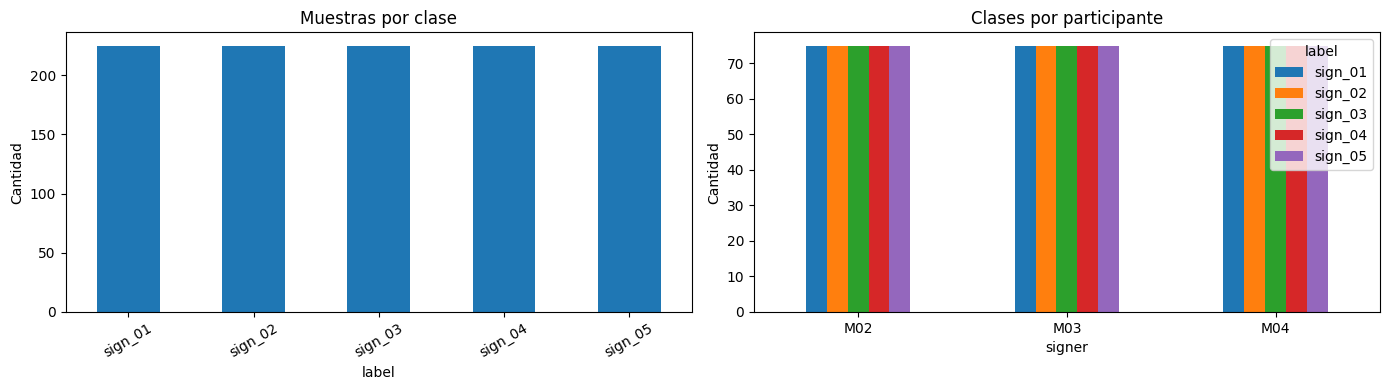

Landmarks con video correspondiente: 1125 / 1125


,label,file,shape,dtype,all_finite
0,sign_01,S01_M02_V01_C01_Clip076.npy,"(62, 1662)",float64,True
1,sign_01,S01_M02_V01_C01_Clip077.npy,"(83, 1662)",float64,True
2,sign_01,S01_M02_V01_C01_Clip078.npy,"(78, 1662)",float64,True
3,sign_02,S02_M02_V01_C02_Clip376.npy,"(69, 1662)",float64,True
4,sign_02,S02_M02_V01_C02_Clip377.npy,"(58, 1662)",float64,True
5,sign_02,S02_M02_V01_C02_Clip378.npy,"(77, 1662)",float64,True
6,sign_03,S03_M02_V01_C03_Clip676.npy,"(59, 1662)",float64,True
7,sign_03,S03_M02_V01_C03_Clip677.npy,"(72, 1662)",float64,True
8,sign_03,S03_M02_V01_C03_Clip678.npy,"(66, 1662)",float64,True
9,sign_04,S04_M02_V01_C04_Clip1000.npy,"(55, 1662)",float64,True


In [4]:
# Resumen de distribución
class_counts = metadata['label'].value_counts().reindex(CLASS_NAMES, fill_value=0)
signer_class = pd.crosstab(metadata['signer'], metadata['label']).reindex(columns=CLASS_NAMES, fill_value=0)
view_counts = metadata['view'].value_counts(dropna=False)

print('Muestras por clase:')
display(class_counts.rename('n').to_frame())
print('Muestras por participante y clase:')
display(signer_class)
print('Muestras por vista:')
display(view_counts.rename('n').to_frame())

# Conteos esperados según el Manual LSC5 para el split público de entrenamiento.
if len(metadata) != 1125:
    warnings.warn(f'Se esperaban 1125 landmarks públicos y se encontraron {len(metadata)}. Verifica la ruta.')
if metadata['signer'].nunique() > 3:
    raise ValueError('Se detectaron más de tres participantes en train. No incluyas el participante reservado para test.')
if not (signer_class == 75).all().all():
    warnings.warn('La distribución no coincide exactamente con 75 muestras por clase y participante; revisa el inventario.')
print('Grupos de ejecución únicos:', metadata['group_id'].nunique())
print('Archivos repetidos por video_id:', int(metadata['video_id'].duplicated().sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
class_counts.plot(kind='bar', ax=axes[0], title='Muestras por clase')
axes[0].set_ylabel('Cantidad'); axes[0].tick_params(axis='x', rotation=30)
signer_class.plot(kind='bar', ax=axes[1], title='Clases por participante')
axes[1].set_ylabel('Cantidad'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

# Comprobación de videos emparejados, si existe la carpeta hermana train/videos.
TRAIN_VIDEO_DIR = TRAIN_LANDMARKS_DIR.parent / 'videos'
if TRAIN_VIDEO_DIR.exists():
    video_stems = {p.stem for p in TRAIN_VIDEO_DIR.rglob('*.mp4')}
    metadata['has_video_pair'] = metadata['video_id'].isin(video_stems)
    print(f"Landmarks con video correspondiente: {metadata['has_video_pair'].sum()} / {len(metadata)}")
else:
    print('No encontré train/videos junto a train/landmarks; se continúa usando los .npy.')

# Inspección de forma y tipo en una muestra de archivos de cada clase.
shape_rows = []
for label in CLASS_NAMES:
    subset = metadata[metadata.label == label].head(3)
    for row in subset.itertuples():
        arr = np.load(row.path, allow_pickle=False)
        shape_rows.append({'label': label, 'file': Path(row.path).name,
                           'shape': arr.shape, 'dtype': str(arr.dtype),
                           'all_finite': bool(np.isfinite(arr).all())})
display(pd.DataFrame(shape_rows))

if metadata['signer'].nunique() != 3:
    warnings.warn(
        f"Se detectaron {metadata['signer'].nunique()} participantes etiquetados; "
        'el manual describe tres participantes públicos. Revisa que hayas agregado el split correcto.'
    )
if set(metadata['label'].unique()) != set(CLASS_NAMES):
    raise ValueError('Faltan clases. Revisa la ruta y la estructura del dataset.')

## 3. Ingeniería de características geométricas y temporales

Cada `.npy` debe contener una matriz `(n_fotogramas, 1662)`, según el manual: pose (132), rostro (1404), mano izquierda (63) y mano derecha (63).

Para reducir ruido y dimensionalidad sin descartar la información útil:

- **Manos:** 21 articulaciones por mano en coordenadas relativas a la muñeca.
- **Trayectoria:** posición de cada muñeca relativa al centro de hombros.
- **Cuerpo:** hombros, codos, muñecas y caderas superiores seleccionadas, normalizadas por el ancho de hombros.
- **Rostro:** un subconjunto pequeño de puntos de cejas, ojos, nariz y boca, relativo a la nariz y normalizado por distancia entre ojos.
- **Dinámica:** diferencias temporales (velocidad aproximada) de todas las características continuas.

La secuencia se remuestrea a `SEQ_LEN = 96` frames (400 características por frame, igual que en el TCN base). Las estadísticas de estandarización se ajustan después, por separado dentro de cada partición de entrenamiento; nunca usando validación o test.

In [5]:
# Índices de la representación descrita en el manual LSC5 / MediaPipe Holistic.
POSE_SLICE = slice(0, 132)
FACE_SLICE = slice(132, 1536)
LEFT_HAND_SLICE = slice(1536, 1599)
RIGHT_HAND_SLICE = slice(1599, 1662)

BODY_JOINTS = [11, 12, 13, 14, 15, 16, 23, 24]  # hombros, codos, muñecas y caderas
FACE_JOINTS = [1, 33, 133, 362, 263, 61, 291, 13, 14, 70, 300]
BASE_FEATURE_DIM = 200
FEATURE_DIM = BASE_FEATURE_DIM * 2  # posición + velocidad
MASK_FEATURES = [197, 198, 199, 397, 398, 399]


def load_landmark_array(path):
    """Carga un .npy y valida la forma esperada (T, 1662)."""
    arr = np.load(path, allow_pickle=False)
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim != 2:
        raise ValueError(f'{path}: esperaba matriz 2D, recibí {arr.shape}')
    if arr.shape[1] != 1662 and arr.shape[0] == 1662:
        arr = arr.T
    if arr.shape[1] != 1662:
        raise ValueError(f'{path}: esperaba 1662 características por frame, recibí {arr.shape}')
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
    if len(arr) < 2:
        raise ValueError(f'{path}: secuencia demasiado corta ({len(arr)} frames)')
    return arr


def resample_frames(arr, target_len=SEQ_LEN):
    """Remuestreo lineal vectorizado a una longitud temporal fija."""
    n = len(arr)
    if n == target_len:
        return arr.astype(np.float32, copy=False)
    positions = np.linspace(0, n - 1, target_len, dtype=np.float32)
    lo = np.floor(positions).astype(np.int64)
    hi = np.minimum(lo + 1, n - 1)
    alpha = (positions - lo).astype(np.float32)[:, None]
    return (arr[lo] * (1.0 - alpha) + arr[hi] * alpha).astype(np.float32)


def landmarks_to_features(arr, target_len=SEQ_LEN):
    """Convierte landmarks crudos en una secuencia (target_len, 400)."""
    arr = resample_frames(arr, target_len)
    t = len(arr)

    pose = arr[:, POSE_SLICE].reshape(t, 33, 4)
    face = arr[:, FACE_SLICE].reshape(t, 468, 3)
    left_hand = arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3)
    right_hand = arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3)

    # Centro del torso y escala robusta por video: distancia entre hombros.
    left_shoulder = pose[:, 11, :3]
    right_shoulder = pose[:, 12, :3]
    torso_center = (left_shoulder + right_shoulder) / 2.0
    shoulder_width = np.linalg.norm(left_shoulder[:, :2] - right_shoulder[:, :2], axis=1)
    valid_widths = shoulder_width[shoulder_width > 1e-4]
    body_scale = float(np.median(valid_widths)) if len(valid_widths) else 1.0
    body_scale = max(body_scale, 1e-3)

    def hand_features(hand):
        present = (np.max(np.abs(hand), axis=(1, 2)) > 1e-6).astype(np.float32)
        wrist = hand[:, 0, :]
        local = (hand - wrist[:, None, :]) / body_scale
        global_wrist = (wrist - torso_center) / body_scale
        local[present == 0] = 0.0
        global_wrist[present == 0] = 0.0
        return local.reshape(t, -1), global_wrist, present

    left_local, left_wrist, left_present = hand_features(left_hand)
    right_local, right_wrist, right_present = hand_features(right_hand)

    # Postura relativa al torso; se conserva visibilidad como cuarta característica.
    body_xyz = (pose[:, BODY_JOINTS, :3] - torso_center[:, None, :]) / body_scale
    body_visibility = pose[:, BODY_JOINTS, 3:4]
    body_features = np.concatenate([body_xyz, body_visibility], axis=2).reshape(t, -1)

    # Rasgos faciales compactos. Se conservan cambios locales respecto a la nariz.
    selected_face = face[:, FACE_JOINTS, :]
    nose = face[:, 1, :]
    eye_width = np.linalg.norm(face[:, 33, :2] - face[:, 263, :2], axis=1)
    valid_eye_widths = eye_width[eye_width > 1e-4]
    face_scale = float(np.median(valid_eye_widths)) if len(valid_eye_widths) else 1.0
    face_scale = max(face_scale, 1e-3)
    face_present = (np.max(np.abs(face), axis=(1, 2)) > 1e-6).astype(np.float32)
    face_local = (selected_face - nose[:, None, :]) / face_scale
    face_local[face_present == 0] = 0.0
    face_features = face_local.reshape(t, -1)

    # 126 mano + 6 trayectorias de muñeca + 32 cuerpo + 33 rostro + 3 máscaras = 200.
    base = np.concatenate([
        left_local, right_local,
        left_wrist, right_wrist,
        body_features, face_features,
        left_present[:, None], right_present[:, None], face_present[:, None]
    ], axis=1).astype(np.float32)

    if base.shape[1] != BASE_FEATURE_DIM:
        raise RuntimeError(f'Dimensión base inesperada: {base.shape[1]}')

    # Diferencias frame a frame. Las máscaras no representan velocidad.
    velocity = np.diff(base, axis=0, prepend=base[:1]).astype(np.float32)
    velocity[:, -3:] = 0.0
    features = np.concatenate([base, velocity], axis=1).astype(np.float32)
    if features.shape != (target_len, FEATURE_DIM):
        raise RuntimeError(f'Dimensión final inesperada: {features.shape}')
    return np.nan_to_num(features, nan=0.0, posinf=0.0, neginf=0.0)


print('Dimensión por frame:', FEATURE_DIM)
print('Máscaras de presencia:', MASK_FEATURES)

# Prueba rápida de procesamiento con un archivo real.
example_path = Path(metadata.iloc[0]['path'])
example_raw = load_landmark_array(example_path)
example_features = landmarks_to_features(example_raw)
print('Archivo de ejemplo:', example_path.name)
print('Forma original:', example_raw.shape)
print('Forma procesada:', example_features.shape)
print('Valores finitos:', np.isfinite(example_features).all())

Dimensión por frame: 400
Máscaras de presencia: [197, 198, 199, 397, 398, 399]
Archivo de ejemplo: S01_M02_V01_C01_Clip076.npy
Forma original: (62, 1662)
Forma procesada: (96, 400)
Valores finitos: True


In [6]:
# 3b. Espejo (lateralidad). Transformacion determinista aplicada a cada muestra por separado.
PAIRS = [(1,4),(2,5),(3,6),(7,8),(9,10),(11,12),(13,14),(15,16),(17,18),(19,20),(21,22),(23,24),(25,26),(27,28),(29,30),(31,32)]
FACE_PAIRS = [(33,263),(133,362),(61,291),(70,300)]  # solo los puntos de rostro que usa el modelo


def _flipx(block):
    """x -> 1-x solo donde el punto existe (los ceros significan 'no detectado')."""
    block = block.copy()
    present = np.abs(block).max(axis=2) > 1e-6
    block[..., 0] = np.where(present, 1.0 - block[..., 0], 0.0)
    return block


def mirror_raw(arr):
    t = len(arr)
    pose = _flipx(arr[:, POSE_SLICE].reshape(t, 33, 4))
    face = _flipx(arr[:, FACE_SLICE].reshape(t, 468, 3))
    lh = _flipx(arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3))
    rh = _flipx(arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3))
    for i, j in PAIRS:
        pose[:, [i, j]] = pose[:, [j, i]]
    for i, j in FACE_PAIRS:
        face[:, [i, j]] = face[:, [j, i]]
    # al espejar, la mano izquierda pasa a ser la derecha y viceversa
    return np.concatenate([pose.reshape(t, -1), face.reshape(t, -1),
                           rh.reshape(t, -1), lh.reshape(t, -1)], axis=1).astype(np.float32)


_ex = load_landmark_array(example_path)
assert np.allclose(mirror_raw(mirror_raw(_ex)), _ex, atol=1e-5), 'espejar dos veces debe devolver el original'
print('Espejo OK (doble espejo = original).')

Espejo OK (doble espejo = original).


## 4. Procesamiento del conjunto etiquetado

En esta celda se transforman los `.npy` del conjunto público de entrenamiento. Guardamos las características procesadas en `/kaggle/working` para facilitar la experimentación durante la sesión.

In [7]:
def build_feature_tensor(meta_df, seq_len=SEQ_LEN):
    """Procesa las muestras etiquetadas y devuelve X, y."""
    sequences = []
    for row in tqdm(meta_df.itertuples(index=False), total=len(meta_df), desc='Procesando landmarks'):
        raw = load_landmark_array(row.path)
        sequences.append(landmarks_to_features(raw, seq_len))
    X_out = np.stack(sequences).astype(np.float32)
    y_out = meta_df['y'].to_numpy(dtype=np.int64)
    return X_out, y_out

X, y = build_feature_tensor(metadata)

# Version espejada de cada muestra (misma etiqueta).
X_mirror = np.stack([landmarks_to_features(mirror_raw(load_landmark_array(p)), SEQ_LEN)
                     for p in tqdm(metadata['path'], desc='Espejando landmarks')]).astype(np.float32)
print('X_mirror:', X_mirror.shape)

print('X:', X.shape, X.dtype)
print('y:', y.shape, y.dtype)
print('Uso aproximado de memoria (MB):', round(X.nbytes / 1024**2, 1))
print('Distribución de etiquetas:', Counter(y.tolist()))

np.save(OUT_DIR / 'X_landmarks_features.npy', X)
np.save(OUT_DIR / 'y_labels.npy', y)
metadata.to_csv(OUT_DIR / 'train_metadata.csv', index=False)
print('Características y metadatos guardados en:', OUT_DIR)

Procesando landmarks:   0%|          | 0/1125 [00:00<?, ?it/s]

Espejando landmarks:   0%|          | 0/1125 [00:00<?, ?it/s]

X_mirror: (1125, 96, 400)
X: (1125, 96, 400) float32
y: (1125,) int64
Uso aproximado de memoria (MB): 164.8
Distribución de etiquetas: Counter({0: 225, 1: 225, 2: 225, 3: 225, 4: 225})
Características y metadatos guardados en: /kaggle/working/lsc5_transformer_artifacts


## 5. Utilidades de escalado y métricas

El escalador se ajusta exclusivamente sobre las secuencias que pertenecen al entrenamiento de cada partición. Cada fold obtiene su propio promedio y desviación estándar.

In [8]:
def fit_sequence_scaler(X_train):
    """Ajusta media y desviación por característica usando solo X_train."""
    flat = X_train.reshape(-1, X_train.shape[-1]).astype(np.float64)
    mean = flat.mean(axis=0).astype(np.float32)
    std = flat.std(axis=0).astype(np.float32)
    std[std < 1e-5] = 1.0
    return {'mean': mean, 'std': std}


def apply_sequence_scaler(X_data, scaler):
    return ((X_data - scaler['mean'][None, None, :]) /
            scaler['std'][None, None, :]).astype(np.float32)


def calculate_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
    }


def print_confusion(y_true, y_pred, title='Matriz de confusión'):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(title)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Etiqueta real')
    ax.set_xticks(range(5), CLASS_NAMES, rotation=35, ha='right')
    ax.set_yticks(range(5), CLASS_NAMES)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout(); plt.show()
    return cm

# Diagnóstico: la longitud temporal ya quedó homogeneizada.
print('Forma de X:', X.shape)
print('Rango global de características:', float(X.min()), 'a', float(X.max()))

Forma de X: (1125, 96, 400)
Rango global de características: -6.649068832397461 a 5.758484840393066


## 6. Línea base: SVM con resumen temporal

Antes de una red neuronal, entrenamos un SVM RBF con estadísticas temporales compactas (media, desviación, mínimo y máximo). Este baseline es rápido y nos indica si las características geométricas ya separan las clases.

La comparación se realiza con exactamente los mismos folds LOSO que utilizaremos para el Transformer.

In [9]:
def summarize_sequences(X_seq):
    """Resume cada secuencia sin perder por completo información de movimiento."""
    mean = X_seq.mean(axis=1)
    std = X_seq.std(axis=1)
    q10 = np.quantile(X_seq, 0.10, axis=1)
    q90 = np.quantile(X_seq, 0.90, axis=1)
    first = X_seq[:, 0, :]
    last = X_seq[:, -1, :]
    return np.concatenate([mean, std, q10, q90, first, last], axis=1).astype(np.float32)


def run_loso_svm(X_seq, y_all, meta_df, X_mir=None):
    signers = sorted(meta_df['signer'].unique())
    X_summary = summarize_sequences(X_seq)
    X_mir_summary = summarize_sequences(X_mir) if X_mir is not None else None
    rows, predictions = [], np.full(len(y_all), -1, dtype=np.int64)

    for heldout in signers:
        train_idx = np.where(meta_df['signer'].to_numpy() != heldout)[0]
        valid_idx = np.where(meta_df['signer'].to_numpy() == heldout)[0]
        model = Pipeline([
            ('scale', StandardScaler()),
            ('svc', SVC(C=2.0, kernel='rbf', class_weight='balanced'))
        ])
        if X_mir_summary is not None:
            model.fit(np.concatenate([X_summary[train_idx], X_mir_summary[train_idx]]),
                      np.concatenate([y_all[train_idx], y_all[train_idx]]))
        else:
            model.fit(X_summary[train_idx], y_all[train_idx])
        pred = model.predict(X_summary[valid_idx])
        predictions[valid_idx] = pred
        metrics = calculate_metrics(y_all[valid_idx], pred)
        rows.append({'heldout_signer': heldout, 'n_valid': len(valid_idx), **metrics})
        print(f"{heldout}: accuracy={metrics['accuracy']:.4f} | macro-F1={metrics['macro_f1']:.4f}")

    return pd.DataFrame(rows), predictions

svm_results, svm_oof = run_loso_svm(X, y, metadata, X_mir=X_mirror if MIRROR_AUG else None)
print('\nResumen SVM LOSO:')
display(svm_results)
print('Accuracy promedio:', round(svm_results.accuracy.mean(), 4),
      '+/-', round(svm_results.accuracy.std(ddof=0), 4))

M02: accuracy=0.9227 | macro-F1=0.9230
M03: accuracy=0.8747 | macro-F1=0.8776
M04: accuracy=0.9120 | macro-F1=0.9098

Resumen SVM LOSO:


,heldout_signer,n_valid,accuracy,macro_f1
0,M02,375,0.922667,0.922992
1,M03,375,0.874667,0.877579
2,M04,375,0.912000,0.909812


Accuracy promedio: 0.9031 +/- 0.0206


## 7. Arquitectura Transformer compacta

La red recibe una secuencia de `SEQ_LEN = 96` frames y 400 características por frame (posición + velocidad).

1. **Proyección por ramas anatómicas:** cada frame se divide en tres subconjuntos (manos, cuerpo, rostro, con los mismos índices que usa el TCN base). Cada rama pasa por `Linear → LayerNorm → GELU` y se concatena en un token de `D_MODEL = 128` (64 manos + 32 cuerpo + 32 rostro). Las manos reciben más capacidad porque concentran la información discriminativa de la seña.
2. **Codificación posicional aprendible:** `nn.Parameter` de forma `(1, SEQ_LEN, D_MODEL)` sumado a los tokens.
3. **`nn.TransformerEncoder`:** 2 capas, 4 cabezas, `dim_feedforward = 256`, `dropout = 0.3`, activación GELU, `batch_first = True`. Se usa `norm_first = True` (pre-LayerNorm) por estabilidad con pocos datos.
4. **Pooling temporal:** atención aprendible (softmax sobre el tiempo) concatenada con el promedio global, seguida de un clasificador lineal a las 5 clases.

Es deliberadamente pequeño (≈0.3 M de parámetros): el dataset tiene solo tres participantes públicos y el riesgo principal es el sobreajuste al firmante.

In [10]:
# Los índices corresponden al orden creado en landmarks_to_features:
# manos (0:132), cuerpo (132:164), rostro (164:197), máscaras (197:200),
# seguidos por sus velocidades (200:400).
HAND_STREAM_IDX = list(range(0, 132)) + list(range(200, 332)) + [197, 198]
BODY_STREAM_IDX = list(range(132, 164)) + list(range(332, 364))
FACE_STREAM_IDX = list(range(164, 197)) + list(range(364, 397)) + [199]


def _branch(n_in, n_out):
    """Proyección de una rama anatómica: Linear -> LayerNorm -> GELU."""
    return nn.Sequential(nn.Linear(n_in, n_out), nn.LayerNorm(n_out), nn.GELU())


class LSC5_Transformer(nn.Module):
    """Transformer compacto sobre landmarks: ramas anatómicas + posición aprendible + encoder + pooling."""
    def __init__(self, input_dim=FEATURE_DIM, seq_len=SEQ_LEN, d_model=D_MODEL,
                 nhead=N_HEADS, num_layers=N_LAYERS, dim_feedforward=FFN_DIM,
                 dropout=DROPOUT, num_classes=5):
        super().__init__()
        if input_dim != FEATURE_DIM:
            raise ValueError(f'input_dim debe ser {FEATURE_DIM}, recibí {input_dim}')
        if HAND_DIM + BODY_DIM + FACE_DIM != d_model:
            raise ValueError('HAND_DIM + BODY_DIM + FACE_DIM debe ser igual a D_MODEL.')

        self.register_buffer('hand_idx', torch.tensor(HAND_STREAM_IDX, dtype=torch.long))
        self.register_buffer('body_idx', torch.tensor(BODY_STREAM_IDX, dtype=torch.long))
        self.register_buffer('face_idx', torch.tensor(FACE_STREAM_IDX, dtype=torch.long))

        # Proyección de entrada por ramas anatómicas hacia D_MODEL.
        self.hand_proj = _branch(len(HAND_STREAM_IDX), HAND_DIM)
        self.body_proj = _branch(len(BODY_STREAM_IDX), BODY_DIM)
        self.face_proj = _branch(len(FACE_STREAM_IDX), FACE_DIM)
        self.fusion_norm = nn.LayerNorm(d_model)

        # Codificación posicional aprendible (1, SEQ_LEN, D_MODEL).
        self.pos_embed = nn.Parameter(torch.zeros(1, seq_len, d_model))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.embed_dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, activation='gelu', batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=num_layers, norm=nn.LayerNorm(d_model),
            enable_nested_tensor=False)

        # Pooling temporal: atención aprendible + promedio global -> clasificador lineal.
        self.attn_pool = nn.Linear(d_model, 1)
        self.classifier = nn.Sequential(
            nn.LayerNorm(d_model * 2),
            nn.Dropout(dropout),
            nn.Linear(d_model * 2, num_classes),
        )

    def forward(self, x):
        # x: (batch, tiempo, características). Cada rama recibe su propio subconjunto.
        if x.shape[1] != self.pos_embed.shape[1]:
            raise ValueError(f'Se esperaban {self.pos_embed.shape[1]} frames y llegaron {x.shape[1]}.')
        tokens = torch.cat([
            self.hand_proj(x.index_select(2, self.hand_idx)),
            self.body_proj(x.index_select(2, self.body_idx)),
            self.face_proj(x.index_select(2, self.face_idx)),
        ], dim=-1)                                              # (B, T, D_MODEL)
        tokens = self.embed_dropout(self.fusion_norm(tokens) + self.pos_embed)

        features = self.encoder(tokens)                         # (B, T, D_MODEL)
        weights = torch.softmax(self.attn_pool(features), dim=1)  # (B, T, 1)
        attended = torch.sum(features * weights, dim=1)
        average = features.mean(dim=1)
        return self.classifier(torch.cat([attended, average], dim=1))


model_test = LSC5_Transformer().to(DEVICE)
params = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
with torch.no_grad():
    dummy = torch.zeros(2, SEQ_LEN, FEATURE_DIM, device=DEVICE)
    dummy_out = model_test(dummy)
print('Dimensiones de ramas:', len(HAND_STREAM_IDX), len(BODY_STREAM_IDX), len(FACE_STREAM_IDX))
print('Posicional:', tuple(model_test.pos_embed.shape))
print('Parámetros entrenables:', f'{params:,}')
print('Salida de prueba:', tuple(dummy_out.shape))
del model_test, dummy, dummy_out

Dimensiones de ramas: 266 64 67
Posicional: (1, 96, 128)
Parámetros entrenables: 301,286
Salida de prueba: (2, 5)


## 8. Entrenamiento, aumento de datos y selección interna de épocas

El aumento de datos es el mismo del TCN base y deliberadamente moderado: pequeñas deformaciones temporales y ruido gaussiano bajo sobre características continuas. La lateralidad SÍ se trata de forma explícita (sección 3b): M02 firma con la mano izquierda y M03/M04 con la derecha, así que también se entrena con versiones espejadas.

**Validación anidada:** para cada participante reservado por LOSO, la selección del número de épocas se hace con **LOSO interno** entre los otros dos participantes (entrenar con uno, validar con el otro, en ambos sentidos; ver R1.2b). Después se crea un modelo nuevo y se entrena con todos los ejemplos de esos dos participantes durante el número de épocas seleccionado. El participante exterior solo se usa para calcular la métrica final del fold.

Optimizador AdamW (`lr = 5e-4`, `weight_decay = 1e-2`), cosine annealing, *label smoothing* 0.03, recorte de gradiente y AMP en GPU. El early stopping usa `PATIENCE = 15` sobre la accuracy de validación interna (desempate por pérdida).

In [11]:
class SequenceDataset(Dataset):
    def __init__(self, X_data, y_data, augment=False):
        self.X = torch.from_numpy(np.asarray(X_data, dtype=np.float32))
        self.y = torch.from_numpy(np.asarray(y_data, dtype=np.int64))
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def _augment_sequence(self, x):
        # Deformación temporal monotónica suave.
        if random.random() < 0.65:
            t = x.shape[0]
            gamma = random.uniform(0.90, 1.10)
            positions = (np.linspace(0, 1, t, dtype=np.float32) ** gamma) * (t - 1)
            lo = np.floor(positions).astype(np.int64)
            hi = np.minimum(lo + 1, t - 1)
            alpha = (positions - lo)[:, None]
            x = x[lo] * (1.0 - alpha) + x[hi] * alpha

        # Ruido pequeño solo en variables continuas, no en máscaras binarias.
        if random.random() < 0.70:
            noise = np.random.normal(0, 0.012, size=x.shape).astype(np.float32)
            noise[:, MASK_FEATURES] = 0.0
            x = x + noise
        return x.astype(np.float32)

    def __getitem__(self, idx):
        x = self.X[idx].numpy().copy()
        if self.augment:
            x = self._augment_sequence(x)
        return torch.from_numpy(x), self.y[idx]


def make_loader(X_data, y_data, train=False):
    dataset = SequenceDataset(X_data, y_data, augment=train)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=train,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == 'cuda'),
        drop_last=False,
    )


def predict_model(model, X_scaled, batch_size=64):
    model.eval()
    outputs = []
    dummy_y = np.zeros(len(X_scaled), dtype=np.int64)
    loader = DataLoader(SequenceDataset(X_scaled, dummy_y, augment=False),
                        batch_size=batch_size, shuffle=False, num_workers=0)
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            outputs.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    return np.concatenate(outputs, axis=0) if outputs else np.empty((0, 5), dtype=np.float32)


def predict_proba(model, scaler, X_raw, X_mir=None):
    """Probabilidades con escalador congelado; promedia con el espejo si MIRROR_TTA."""
    p = predict_model(model, apply_sequence_scaler(X_raw, scaler))
    if MIRROR_TTA and X_mir is not None:
        p = (p + predict_model(model, apply_sequence_scaler(X_mir, scaler))) / 2.0
    return p


def fit_model(X_train_raw, y_train, X_valid_raw=None, y_valid=None,
              max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED):
    """Ajusta scaler solo con train y entrena el Transformer. Si hay validación, aplica early stopping."""
    seed_everything(seed)
    scaler = fit_sequence_scaler(X_train_raw)
    X_train = apply_sequence_scaler(X_train_raw, scaler)
    train_loader = make_loader(X_train, y_train, train=True)

    has_valid = X_valid_raw is not None and y_valid is not None
    if has_valid:
        X_valid = apply_sequence_scaler(X_valid_raw, scaler)
        valid_loader = make_loader(X_valid, y_valid, train=False)

    model = LSC5_Transformer().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.03)
    amp_enabled = bool(USE_AMP and DEVICE.type == 'cuda')
    try:
        grad_scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
    except (AttributeError, TypeError):
        grad_scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

    best_epoch = max_epochs
    best_accuracy = -1.0
    best_loss = float('inf')
    best_state = None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, max_epochs + 1):
        model.train()
        running_loss, seen = 0.0, 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                logits = model(xb)
                loss = criterion(logits, yb)
            grad_scaler.scale(loss).backward()
            grad_scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            grad_scaler.step(optimizer)
            grad_scaler.update()
            running_loss += float(loss.item()) * len(yb)
            seen += len(yb)

        train_loss = running_loss / max(seen, 1)
        row = {'epoch': epoch, 'train_loss': train_loss}

        if has_valid:
            model.eval()
            val_loss_sum, val_seen, val_pred, val_true = 0.0, 0, [], []
            with torch.no_grad():
                for xb, yb in valid_loader:
                    xb = xb.to(DEVICE, non_blocking=True)
                    yb = yb.to(DEVICE, non_blocking=True)
                    with torch.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                        logits = model(xb)
                        loss = criterion(logits, yb)
                    val_loss_sum += float(loss.item()) * len(yb)
                    val_seen += len(yb)
                    val_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
                    val_true.extend(yb.cpu().numpy().tolist())

            val_loss = val_loss_sum / max(val_seen, 1)
            val_acc = accuracy_score(val_true, val_pred)
            row.update({'val_loss': val_loss, 'val_accuracy': val_acc})
            improved = (val_acc > best_accuracy + 1e-6) or (
                abs(val_acc - best_accuracy) <= 1e-6 and val_loss < best_loss
            )
            if improved:
                best_accuracy, best_loss = float(val_acc), float(val_loss)
                best_epoch = epoch
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
        else:
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        history.append(row)
        scheduler.step()

        if has_valid and epochs_without_improvement >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, scaler, int(best_epoch), pd.DataFrame(history)


print('Funciones de entrenamiento definidas. AMP:', USE_AMP and DEVICE.type == 'cuda')

Funciones de entrenamiento definidas. AMP: True


## 9. Validación LOSO anidada del Transformer (multi-semilla)

Cada fold reserva un participante completo. El LOSO interno sirve únicamente para decidir el número de épocas. Después el modelo se reinicia, ajusta su escalador con los dos participantes del fold (más sus espejos) y se entrena con todos ellos durante las épocas seleccionadas.

Así, las muestras del participante exterior no participan en el escalado, early stopping ni actualización de pesos. El bucle verifica con `assert` que el firmante reservado nunca aparece en el train del fold.

El procedimiento completo se repite para cada semilla de `SEEDS`. Se guardan las probabilidades OOF de cada semilla; el **ensamble** promedia las probabilidades de las semillas para cada muestra reservada (sigue sin fuga: cada probabilidad proviene de un modelo que no vio a ese firmante).


SEMILLA 42

[seed=42] FOLD 1/3 | participante reservado: M02
  LOSO interno val=M03: mejor epoca 18
  LOSO interno val=M04: mejor epoca 60
  Epocas seleccionadas (media interna): 39
  [seed=42] Resultado M02: accuracy=1.0000 | macro-F1=1.0000 | 164s

[seed=42] FOLD 2/3 | participante reservado: M03
  LOSO interno val=M02: mejor epoca 57
  LOSO interno val=M04: mejor epoca 21
  Epocas seleccionadas (media interna): 39
  [seed=42] Resultado M03: accuracy=0.9333 | macro-F1=0.9314 | 160s

[seed=42] FOLD 3/3 | participante reservado: M04
  LOSO interno val=M02: mejor epoca 49
  LOSO interno val=M03: mejor epoca 32
  Epocas seleccionadas (media interna): 40
  [seed=42] Resultado M04: accuracy=0.9280 | macro-F1=0.9266 | 164s

SEMILLA 7

[seed=7] FOLD 1/3 | participante reservado: M02
  LOSO interno val=M03: mejor epoca 47
  LOSO interno val=M04: mejor epoca 36
  Epocas seleccionadas (media interna): 42
  [seed=7] Resultado M02: accuracy=1.0000 | macro-F1=1.0000 | 169s

[seed=7] FOLD 2/3 | pa

,seed,heldout_signer,n_valid,best_epochs,accuracy,macro_f1
0,42,M02,375,39,1.000000,1.000000
1,42,M03,375,39,0.933333,0.931429
2,42,M04,375,40,0.928000,0.926602
3,7,M02,375,42,1.000000,1.000000
4,7,M03,375,12,0.933333,0.931429
5,7,M04,375,31,0.920000,0.920678
6,123,M02,375,16,0.970667,0.970548
7,123,M03,375,30,0.912000,0.910820
8,123,M04,375,26,0.949333,0.949382


Resumen por fold (media/desv. entre semillas):


,heldout_signer,accuracy_mean,accuracy_std,macro_f1_mean,epochs_mean
0,M02,0.990222,0.013828,0.990183,32.333333
1,M03,0.926222,0.010057,0.924559,27.000000
2,M04,0.932444,0.012381,0.932220,32.333333


Resumen por semilla (media LOSO):


,seed,mean_accuracy,worst_fold_accuracy,mean_macro_f1
0,7,0.951111,0.920,0.950702
1,42,0.953778,0.928,0.952677
2,123,0.944000,0.912,0.943583


Accuracy LOSO media entre semillas: 0.9496 +/- 0.0041

Ensamble de semillas por fold:


,heldout_signer,n_valid,accuracy,macro_f1
0,M02,375,0.997333,0.997333
1,M03,375,0.930667,0.928762
2,M04,375,0.925333,0.925760


Accuracy promedio (ensamble): 0.9511 +/- 0.0328
Épocas seleccionadas por semilla: {42: [39, 39, 40], 7: [42, 12, 31], 123: [16, 30, 26]}
Accuracy OOF agregado (ensamble): 0.9511
Macro-F1 OOF agregado (ensamble): 0.9501
              precision    recall  f1-score   support

     sign_01       1.00      0.99      0.99       225
     sign_02       0.90      1.00      0.95       225
     sign_03       0.99      1.00      0.99       225
     sign_04       0.90      0.97      0.93       225
     sign_05       0.99      0.80      0.89       225

    accuracy                           0.95      1125
   macro avg       0.96      0.95      0.95      1125
weighted avg       0.96      0.95      0.95      1125



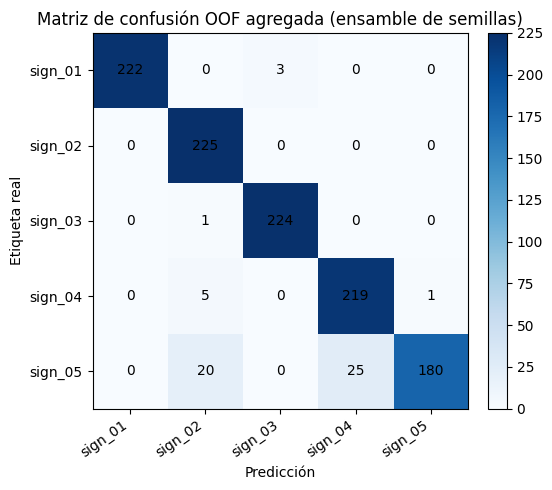

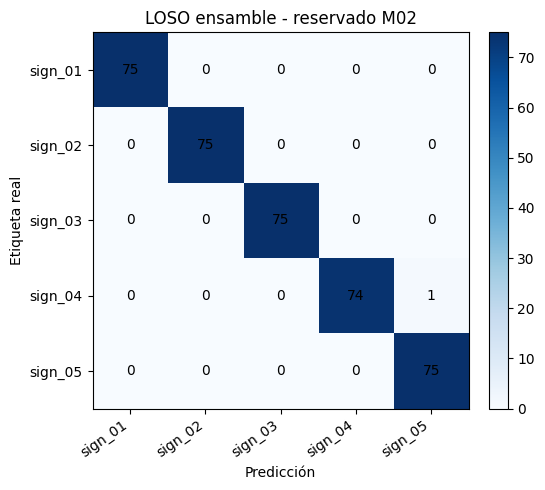

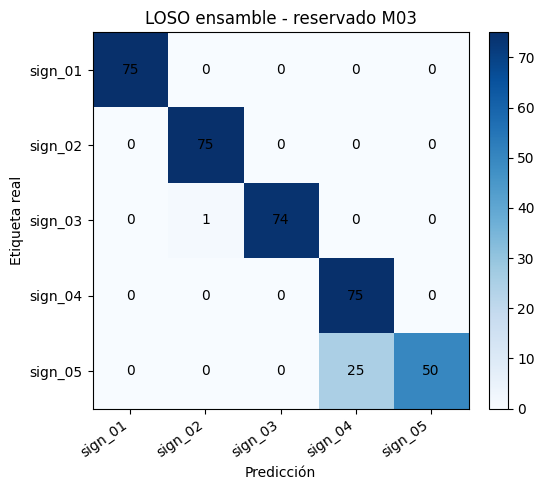

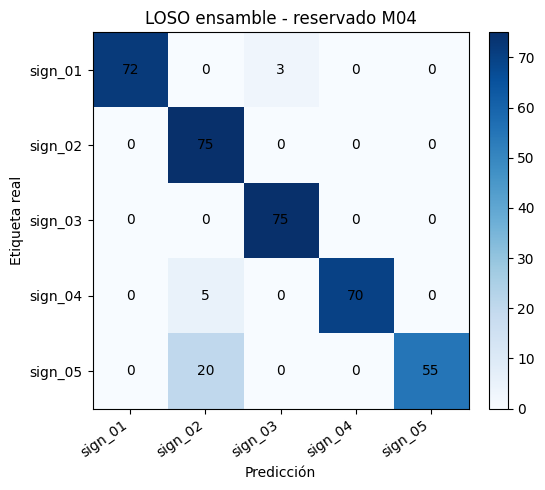

In [12]:
def run_loso_transformer(X_seq, y_all, meta_df, X_mir, seed):
    """LOSO anidado para una semilla. Devuelve filas por fold, probabilidades OOF, épocas e historiales internos."""
    def with_mirror(idx):
        if MIRROR_AUG:
            return np.concatenate([X_seq[idx], X_mir[idx]]), np.concatenate([y_all[idx], y_all[idx]])
        return X_seq[idx], y_all[idx]

    signers = sorted(meta_df['signer'].unique())
    if len(signers) < 3:
        warnings.warn(f'Se detectaron {len(signers)} participantes; LOSO se ejecutará con los disponibles.')

    signer_values = meta_df['signer'].to_numpy()
    fold_rows, best_epochs, hist_frames = [], [], []
    oof_proba = np.full((len(y_all), len(CLASS_NAMES)), np.nan, dtype=np.float32)

    for fold_no, heldout in enumerate(signers, start=1):
        t0 = time.time()
        print(f'\n[seed={seed}] FOLD {fold_no}/{len(signers)} | participante reservado: {heldout}')
        outer_train_idx = np.where(signer_values != heldout)[0]
        outer_valid_idx = np.where(signer_values == heldout)[0]
        assert heldout not in set(signer_values[outer_train_idx]), 'El firmante reservado aparece en train.'

        # LOSO interno: los numeros de Clip NO identifican ejecuciones entre vistas (cada archivo
        # tiene un Clip unico), asi que un split aleatorio "agrupado" filtraria vistas. Se entrena
        # con uno de los dos participantes y se valida con el otro, en ambos sentidos.
        inner_signers = sorted(set(signer_values[outer_train_idx]))
        inner_epochs = []
        for s_val in inner_signers:
            itr = outer_train_idx[signer_values[outer_train_idx] != s_val]
            iva = outer_train_idx[signer_values[outer_train_idx] == s_val]
            assert not (set(signer_values[itr]) & set(signer_values[iva])), 'Fuga en LOSO interno.'
            Xi, yi = with_mirror(itr)
            _, _, be, hist = fit_model(Xi, yi, X_seq[iva], y_all[iva],
                                       max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=seed + fold_no)
            inner_epochs.append(be)
            hist = hist.assign(seed=seed, heldout_signer=heldout, inner_val_signer=s_val)
            hist_frames.append(hist)
            print(f'  LOSO interno val={s_val}: mejor epoca {be}')
        best_epoch = max(1, int(round(float(np.mean(inner_epochs)))))
        best_epochs.append(best_epoch)
        print('  Epocas seleccionadas (media interna):', best_epoch)

        # 2) Reentrenamiento desde cero con los dos participantes completos.
        Xo, yo = with_mirror(outer_train_idx)
        fold_model, fold_scaler, _, _ = fit_model(
            Xo, yo,
            X_valid_raw=None, y_valid=None,
            max_epochs=best_epoch, patience=best_epoch, seed=seed + 100 + fold_no
        )

        # 3) Evaluación una sola vez sobre el participante reservado.
        probabilities = predict_proba(fold_model, fold_scaler, X_seq[outer_valid_idx], X_mir[outer_valid_idx])
        oof_proba[outer_valid_idx] = probabilities
        predictions = probabilities.argmax(axis=1)
        metrics = calculate_metrics(y_all[outer_valid_idx], predictions)
        fold_rows.append({
            'seed': seed,
            'heldout_signer': heldout,
            'n_train': len(outer_train_idx),
            'n_valid': len(outer_valid_idx),
            'inner_split': 'LOSO interno',
            'best_epochs': best_epoch,
            **metrics,
        })
        print(f"  [seed={seed}] Resultado {heldout}: accuracy={metrics['accuracy']:.4f} | "
              f"macro-F1={metrics['macro_f1']:.4f} | {time.time() - t0:.0f}s")

        del fold_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    if np.isnan(oof_proba).any():
        warnings.warn('Hay observaciones sin predicción OOF; revisa el inventario de participantes.')
    return fold_rows, oof_proba, best_epochs, pd.concat(hist_frames, ignore_index=True)


# Ejecuta los tres folds para cada semilla. En GPU T4/P100 es razonable; en CPU reduce SEEDS y MAX_EPOCHS.
all_rows, oof_proba_by_seed, epochs_by_seed, inner_histories = [], {}, {}, []
for s in SEEDS:
    print('\n' + '=' * 72)
    print(f'SEMILLA {s}')
    print('=' * 72)
    rows_s, oof_s, epochs_s, hist_s = run_loso_transformer(X, y, metadata, X_mirror, seed=s)
    all_rows.extend(rows_s)
    oof_proba_by_seed[s] = oof_s
    epochs_by_seed[s] = epochs_s
    inner_histories.append(hist_s)

transformer_results = pd.DataFrame(all_rows)
inner_histories = pd.concat(inner_histories, ignore_index=True)

print('\n' + '=' * 72)
print('Resultados por semilla y fold (Transformer):')
display(transformer_results[['seed', 'heldout_signer', 'n_valid', 'best_epochs', 'accuracy', 'macro_f1']])

# Resumen por fold: media y desviación entre semillas.
fold_summary = (transformer_results.groupby('heldout_signer')
                .agg(accuracy_mean=('accuracy', 'mean'), accuracy_std=('accuracy', lambda v: float(np.std(v, ddof=0))),
                     macro_f1_mean=('macro_f1', 'mean'), epochs_mean=('best_epochs', 'mean'))
                .reset_index())
print('Resumen por fold (media/desv. entre semillas):')
display(fold_summary)

seed_summary = transformer_results.groupby('seed').agg(
    mean_accuracy=('accuracy', 'mean'), worst_fold_accuracy=('accuracy', 'min'),
    mean_macro_f1=('macro_f1', 'mean')).reset_index()
print('Resumen por semilla (media LOSO):')
display(seed_summary)
print('Accuracy LOSO media entre semillas:', round(seed_summary.mean_accuracy.mean(), 4),
      '+/-', round(seed_summary.mean_accuracy.std(ddof=0), 4))

# Ensamble de semillas: promedio de probabilidades OOF.
proba_stack = np.stack([oof_proba_by_seed[s] for s in SEEDS])           # (n_seeds, N, 5)
ens_proba = proba_stack.mean(axis=0)
tr_oof = ens_proba.argmax(axis=1)                                       # predicción OOF del ensamble
signer_values_all = metadata['signer'].to_numpy()
ens_rows = []
for heldout in sorted(metadata['signer'].unique()):
    m = signer_values_all == heldout
    ens_rows.append({'heldout_signer': heldout, 'n_valid': int(m.sum()),
                     **calculate_metrics(y[m], tr_oof[m])})
transformer_ens_results = pd.DataFrame(ens_rows)
print('\nEnsamble de semillas por fold:')
display(transformer_ens_results)
print('Accuracy promedio (ensamble):', round(transformer_ens_results.accuracy.mean(), 4),
      '+/-', round(transformer_ens_results.accuracy.std(ddof=0), 4))

all_epochs = [e for s in SEEDS for e in epochs_by_seed[s]]
print('Épocas seleccionadas por semilla:', {s: epochs_by_seed[s] for s in SEEDS})
print('Accuracy OOF agregado (ensamble):', round(accuracy_score(y, tr_oof), 4))
print('Macro-F1 OOF agregado (ensamble):', round(f1_score(y, tr_oof, average='macro'), 4))
print(classification_report(y, tr_oof, labels=list(range(5)), target_names=CLASS_NAMES, zero_division=0))
print_confusion(y, tr_oof, 'Matriz de confusión OOF agregada (ensamble de semillas)')
for heldout in sorted(metadata['signer'].unique()):
    m = signer_values_all == heldout
    print_confusion(y[m], tr_oof[m], f'LOSO ensamble - reservado {heldout}')

## 10. Comparación y decisión del modelo

La métrica principal es Accuracy Top-1. Macro-F1, desempeño por participante y matrices de confusión ayudan a identificar fallos concentrados.

No debemos escoger un modelo por una única partición ni por una única semilla. Revisamos promedio y dispersión entre los tres participantes y entre semillas, y miramos el peor participante. El SVM es un control: si supera al Transformer, no se debe forzar la red neuronal.

Aquí se compara contra el SVM de este mismo notebook. Los artefactos guardados (resultados por fold, predicciones OOF y probabilidades) siguen el mismo esquema que el notebook TCN para la comparación conjunta SVM / TCN / Transformer en **T9**.

In [13]:
per_seed_oof_acc = [accuracy_score(y, oof_proba_by_seed[s].argmax(axis=1)) for s in SEEDS]
comparison = pd.DataFrame([
    {'model': 'SVM-RBF',
     'mean_accuracy': svm_results.accuracy.mean(),
     'std_accuracy': svm_results.accuracy.std(ddof=0),
     'worst_fold_accuracy': svm_results.accuracy.min(),
     'mean_macro_f1': svm_results.macro_f1.mean()},
    {'model': f'Transformer (media de {len(SEEDS)} semillas)',
     'mean_accuracy': seed_summary.mean_accuracy.mean(),
     'std_accuracy': transformer_results.groupby('heldout_signer').accuracy.mean().std(ddof=0),
     'worst_fold_accuracy': transformer_results.groupby('heldout_signer').accuracy.mean().min(),
     'mean_macro_f1': seed_summary.mean_macro_f1.mean()},
    {'model': 'Transformer (ensamble de semillas)',
     'mean_accuracy': transformer_ens_results.accuracy.mean(),
     'std_accuracy': transformer_ens_results.accuracy.std(ddof=0),
     'worst_fold_accuracy': transformer_ens_results.accuracy.min(),
     'mean_macro_f1': transformer_ens_results.macro_f1.mean()},
]).sort_values('mean_accuracy', ascending=False)
display(comparison)
print('std_accuracy: desviación entre participantes (folds LOSO).')

print('Accuracy por participante y semilla:')
display(transformer_results.pivot(index='heldout_signer', columns='seed', values='accuracy'))

# Regla de decisión: la opción con mayor accuracy media LOSO es la referencia.
# Si hay diferencias mínimas, considerar estabilidad (menor desviación), peor participante y macro-F1.
if seed_summary.mean_accuracy.mean() >= svm_results.accuracy.mean():
    print('El Transformer iguala o supera el baseline SVM en accuracy media LOSO.')
else:
    print('El SVM supera al Transformer en accuracy media LOSO. Revisar el modelo y no asumir que la red es mejor.')

# Guardar resultados y predicciones OOF para auditoría/reporte y para T9.
svm_results.to_csv(OUT_DIR / 'loso_svm_results.csv', index=False)
transformer_results.to_csv(OUT_DIR / 'loso_transformer_results.csv', index=False)            # por semilla y fold
transformer_ens_results.to_csv(OUT_DIR / 'loso_transformer_ensemble_results.csv', index=False)  # ensamble por fold
fold_summary.to_csv(OUT_DIR / 'loso_transformer_fold_summary.csv', index=False)
seed_summary.to_csv(OUT_DIR / 'loso_transformer_seed_summary.csv', index=False)
comparison.to_csv(OUT_DIR / 'comparison_svm_vs_transformer.csv', index=False)
inner_histories.to_csv(OUT_DIR / 'transformer_inner_histories.csv', index=False)

oof_df = pd.DataFrame({'video_id': metadata['video_id'], 'signer': metadata['signer'],
                       'true_sign': metadata['label'],
                       'predicted_sign': [ID_TO_CLASS[int(v)] for v in tr_oof]})   # ensamble (mismo esquema que el TCN)
for s in SEEDS:
    oof_df[f'predicted_sign_seed{s}'] = [ID_TO_CLASS[int(v)] for v in oof_proba_by_seed[s].argmax(axis=1)]
oof_df.to_csv(OUT_DIR / 'transformer_oof_predictions.csv', index=False)
np.save(OUT_DIR / 'transformer_oof_proba_by_seed.npy', proba_stack)                    # (n_seeds, N, 5), orden SEEDS
np.save(OUT_DIR / 'transformer_oof_proba_ensemble.npy', ens_proba)                     # (N, 5)

with open(OUT_DIR / 'selected_epochs.json', 'w', encoding='utf-8') as f:
    json.dump({'best_epochs_by_seed_and_fold': {str(s): [int(v) for v in epochs_by_seed[s]] for s in SEEDS},
               'folds_order': sorted(metadata['signer'].unique().tolist()),
               'median_epochs': int(np.median(all_epochs))}, f, indent=2)
print('Resultados guardados en:', OUT_DIR)

,model,mean_accuracy,std_accuracy,worst_fold_accuracy,mean_macro_f1
2,Transformer (ensamble de semillas),0.951111,0.032756,0.925333,0.950618
1,Transformer (media de 3 semillas),0.949630,0.028815,0.926222,0.948987
0,SVM-RBF,0.903111,0.020579,0.874667,0.903461


std_accuracy: desviación entre participantes (folds LOSO).
Accuracy por participante y semilla:


seed,7,42,123
heldout_signer,,,
M02,1.000000,1.000000,0.970667
M03,0.933333,0.933333,0.912000
M04,0.920000,0.928000,0.949333


El Transformer iguala o supera el baseline SVM en accuracy media LOSO.
Resultados guardados en: /kaggle/working/lsc5_transformer_artifacts


## 11. Entrenamiento final con los tres participantes públicos

Una vez terminada la comparación LOSO y congelados los hiperparámetros, entrenamos un modelo final **por semilla** con **todos los ejemplos etiquetados disponibles** (más sus espejos). El número de épocas es la mediana global de las épocas seleccionadas en los LOSO internos (todas las semillas y folds).

La inferencia final promedia las probabilidades de los modelos de las tres semillas (cada uno con su propio escalador ajustado solo con el train completo). No se utiliza el test para modificar pesos, normalización, umbrales o hiperparámetros.

In [14]:
FINAL_EPOCHS = max(1, int(np.median(all_epochs)))
print('Épocas finales (mediana de LOSO, todas las semillas):', FINAL_EPOCHS)

X_final, y_final = (np.concatenate([X, X_mirror]), np.concatenate([y, y])) if MIRROR_AUG else (X, y)

MODEL_CONFIG = {
    'architecture': 'LSC5_Transformer',
    'seq_len': SEQ_LEN,
    'feature_dim': FEATURE_DIM,
    'base_feature_dim': BASE_FEATURE_DIM,
    'd_model': D_MODEL,
    'branch_dims': {'hand': HAND_DIM, 'body': BODY_DIM, 'face': FACE_DIM},
    'num_layers': N_LAYERS,
    'nhead': N_HEADS,
    'dim_feedforward': FFN_DIM,
    'dropout': DROPOUT,
    'activation': 'gelu',
    'norm_first': True,
    'batch_size': BATCH_SIZE,
    'max_epochs': MAX_EPOCHS,
    'patience': PATIENCE,
    'learning_rate': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY,
    'classes': CLASS_NAMES,
    'final_epochs': FINAL_EPOCHS,
    'seeds': SEEDS,
    'mirror_aug': MIRROR_AUG,
    'mirror_tta': MIRROR_TTA,
}

final_ensemble = []   # lista de (modelo, escalador) usada por la inferencia final
for s in SEEDS:
    m_final, sc_final, _, hist_final = fit_model(
        X_final, y_final,
        X_valid_raw=None, y_valid=None,
        max_epochs=FINAL_EPOCHS, patience=FINAL_EPOCHS,
        seed=s + 999
    )
    final_ensemble.append((m_final, sc_final))
    torch.save({
        'model_state_dict': m_final.state_dict(),
        'scaler_mean': sc_final['mean'],
        'scaler_std': sc_final['std'],
        'config': {**MODEL_CONFIG, 'seed': s},
    }, OUT_DIR / f'lsc5_transformer_final_seed{s}.pt')
    hist_final.to_csv(OUT_DIR / f'final_training_history_seed{s}.csv', index=False)
    print(f'Modelo final guardado (semilla {s}):', OUT_DIR / f'lsc5_transformer_final_seed{s}.pt')

with open(OUT_DIR / 'model_config.json', 'w', encoding='utf-8') as f:
    json.dump(MODEL_CONFIG, f, indent=2, ensure_ascii=False)

with open(OUT_DIR / 'run_summary.json', 'w', encoding='utf-8') as f:
    json.dump({
        'model': 'LSC5_Transformer',
        'trainable_params': int(sum(p.numel() for p in final_ensemble[0][0].parameters() if p.requires_grad)),
        'loso_accuracy_mean_over_seeds': float(seed_summary.mean_accuracy.mean()),
        'loso_accuracy_std_over_seeds': float(seed_summary.mean_accuracy.std(ddof=0)),
        'loso_accuracy_ensemble_mean': float(transformer_ens_results.accuracy.mean()),
        'loso_accuracy_by_signer_ensemble': {r.heldout_signer: float(r.accuracy)
                                             for r in transformer_ens_results.itertuples()},
        'oof_accuracy_ensemble': float(accuracy_score(y, tr_oof)),
        'oof_macro_f1_ensemble': float(f1_score(y, tr_oof, average='macro')),
        'svm_loso_accuracy_mean': float(svm_results.accuracy.mean()),
        'config': MODEL_CONFIG,
    }, f, indent=2, ensure_ascii=False)

print('Artefactos disponibles:')
for p in sorted(OUT_DIR.iterdir()):
    print('-', p.name, f'({p.stat().st_size / 1024**2:.2f} MB)')

Épocas finales (mediana de LOSO, todas las semillas): 31
Modelo final guardado (semilla 42): /kaggle/working/lsc5_transformer_artifacts/lsc5_transformer_final_seed42.pt
Modelo final guardado (semilla 7): /kaggle/working/lsc5_transformer_artifacts/lsc5_transformer_final_seed7.pt
Modelo final guardado (semilla 123): /kaggle/working/lsc5_transformer_artifacts/lsc5_transformer_final_seed123.pt
Artefactos disponibles:
- X_landmarks_features.npy (164.80 MB)
- comparison_svm_vs_transformer.csv (0.00 MB)
- final_training_history_seed123.csv (0.00 MB)
- final_training_history_seed42.csv (0.00 MB)
- final_training_history_seed7.csv (0.00 MB)
- loso_svm_results.csv (0.00 MB)
- loso_transformer_ensemble_results.csv (0.00 MB)
- loso_transformer_fold_summary.csv (0.00 MB)
- loso_transformer_results.csv (0.00 MB)
- loso_transformer_seed_summary.csv (0.00 MB)
- lsc5_transformer_final_seed123.pt (1.18 MB)
- lsc5_transformer_final_seed42.pt (1.18 MB)
- lsc5_transformer_final_seed7.pt (1.18 MB)
- model_c

## 12. Inferencia final sobre test (opcional y estrictamente separada)

**No ejecutar hasta congelar el modelo y cerrar la selección de hiperparámetros.** Esta celda no calcula métricas, no adapta el escalador y no modifica el modelo. Solo aplica la transformación determinista ya definida y genera una predicción por ID, promediando los modelos finales de las semillas.

Por defecto `RUN_FINAL_TEST_INFERENCE = False`. Para generar `submission.csv`, cambia esa variable a `True` y ejecuta únicamente después de completar las fases anteriores.

In [15]:
def discover_test_landmarks(root=DATA_ROOT, override=None):
    if override is not None:
        p = Path(override)
        if not p.exists():
            raise FileNotFoundError(f'La ruta TEST_LANDMARKS_DIR no existe: {p}')
        return p
    candidates = []
    for p in root.rglob('landmarks'):
        if not p.is_dir():
            continue
        if 'test' in [part.lower() for part in p.parts] and any(p.rglob('*.npy')):
            candidates.append(p)
    if not candidates:
        raise FileNotFoundError('No encontré test/landmarks. Define TEST_LANDMARKS_DIR manualmente.')
    candidates.sort(key=lambda p: len(str(p)))
    return candidates[0]


def build_test_features(test_dir):
    paths = sorted(Path(test_dir).rglob('*.npy'))
    if not paths:
        raise RuntimeError(f'No hay .npy en {test_dir}')
    ids, feats, mfeats = [], [], []
    for p in tqdm(paths, desc='Inferencia: transformando test'):
        ids.append(p.stem)
        raw = load_landmark_array(p)
        feats.append(landmarks_to_features(raw, SEQ_LEN))
        mfeats.append(landmarks_to_features(mirror_raw(raw), SEQ_LEN))  # transformacion determinista por muestra
    return (pd.DataFrame({'video_id': ids, 'path': [str(p) for p in paths]}),
            np.stack(feats).astype(np.float32), np.stack(mfeats).astype(np.float32))


def predict_ensemble(models_and_scalers, X_raw, X_mir):
    """Promedia las probabilidades de los modelos finales (cada uno con su escalador congelado)."""
    return np.mean([predict_proba(m, sc, X_raw, X_mir) for m, sc in models_and_scalers], axis=0)


def generate_submission(models_and_scalers, test_dir, out_dir=OUT_DIR):
    """Solo inferencia. No usa etiquetas ni estadísticas del conjunto de test."""
    test_meta, X_test, X_test_mirror = build_test_features(test_dir)
    probabilities = predict_ensemble(models_and_scalers, X_test, X_test_mirror)  # escaladores congelados del train completo
    pred_ids = probabilities.argmax(axis=1)
    submission = pd.DataFrame({
        'video_id': test_meta['video_id'],
        'predicted_sign': [ID_TO_CLASS[int(i)] for i in pred_ids]
    })

    # Si existe plantilla, se respeta exactamente su orden e IDs.
    templates = list(DATA_ROOT.rglob('submission_template.csv'))
    if templates:
        template = pd.read_csv(templates[0])
        if 'video_id' not in template.columns:
            raise ValueError('La plantilla no contiene columna video_id.')
        submission = template[['video_id']].merge(submission, on='video_id', how='left', validate='one_to_one')
        if submission['predicted_sign'].isna().any():
            raise ValueError('Hay IDs de plantilla sin predicción. Revisa los archivos de test.')

    if submission['video_id'].duplicated().any():
        raise ValueError('Hay video_id duplicados en la entrega.')
    if submission['predicted_sign'].isna().any():
        raise ValueError('Hay predicciones vacías.')
    if not set(submission['predicted_sign']).issubset(set(CLASS_NAMES)):
        raise ValueError('Se generó una etiqueta no permitida.')

    output_path = Path(out_dir) / 'submission.csv'
    submission.to_csv(output_path, index=False, encoding='utf-8')
    print('CSV generado:', output_path)
    print('Filas:', len(submission))
    print('Columnas:', submission.columns.tolist())
    display(submission.head())
    return submission


if RUN_FINAL_TEST_INFERENCE:
    TEST_LANDMARKS_DIR = discover_test_landmarks(DATA_ROOT, TEST_LANDMARKS_DIR)
    submission = generate_submission(final_ensemble, TEST_LANDMARKS_DIR)
else:
    print('Inferencia de test desactivada. No se ha leído ningún archivo de test.')

Inferencia de test desactivada. No se ha leído ningún archivo de test.


In [16]:
import shutil
shutil.make_archive('/kaggle/working/resultados_transformer', 'zip', '/kaggle/working/lsc5_transformer_artifacts')
print("ZIP listo para descargar")

ZIP listo para descargar


## 13. Checklist antes de entregar

- [ ] Se verificó que `train/landmarks` contiene únicamente los tres participantes públicos.
- [ ] Se inspeccionaron formas, valores faltantes y correspondencia de los `.npy`.
- [ ] Los tres folds LOSO reservaron un participante completo (en las tres semillas).
- [ ] La selección de épocas usó LOSO interno entre los dos participantes de entrenamiento (no un split aleatorio que filtre vistas).
- [ ] El escalador se ajustó solo con el subconjunto de entrenamiento de cada partición.
- [ ] Se registraron Accuracy Top-1 y macro-F1 por participante y por semilla.
- [ ] Se comparó el Transformer contra el SVM sin mirar resultados de test; los CSV/NPY de `lsc5_transformer_artifacts` quedan listos para T9 (SVM vs TCN vs Transformer).
- [ ] Se congelaron hiperparámetros antes de ejecutar inferencia final.
- [ ] Se verificó el espejo (doble espejo = original) y que M02 (zurdo) mejora en LOSO.
- [ ] `RUN_FINAL_TEST_INFERENCE` permaneció en `False` durante todo el desarrollo (no se leyó ningún archivo de test).
- [ ] El CSV final tiene `video_id,predicted_sign`, sin índice, duplicados ni IDs faltantes.
- [ ] Se conserva el notebook, los pesos (uno por semilla), la configuración y los resultados OOF para auditoría.

## Ajustes posteriores

Este notebook ya usa la configuración de GPU propuesta para T7 (`SEQ_LEN = 96`, `MAX_EPOCHS = 80`, 3 semillas). Para explorar variantes (`D_MODEL`, `N_LAYERS`, `DROPOUT`, `LEARNING_RATE`) en una nueva corrida versionada, cambia un hiperparámetro a la vez y vuelve a evaluar con los tres folds LOSO. No adoptes una variante más grande salvo que mejore el promedio y no deteriore notablemente el peor participante.

**Importante:** el número final de épocas y cualquier mejora deben salir de experimentos ejecutados. Este notebook no presupone ni promete una accuracy específica.